# Notebook 3 — Construction du CNN 1D, brique par brique

**Objectif.** Construire un réseau qui lit les deux séries (T_int, U) et prédit les 5 cibles normalisées (HLC_mit, HLC_ext, log τ_b, log τ_n, log τ_inf), puis vérifier chaque brique avant de l'entraîner.

**Barre à battre** (baseline linéaire degré 2, validation) : MAPE HLC 8,6 %, HLC_mit 16,0 %, HLC_ext 10,8 %, τ_b 15,4 %, τ_n 12,6 %, τ_inf 18,5 %.

| Étape | Brique | Vérification |
|---|---|---|
| 1 | Les données côté modèle | formes (B, 2, 480) → (B, 5) |
| 2 | Une couche Conv1d | un filtre = une réponse impulsionnelle |
| 3 | Le bloc résiduel et le champ réceptif | le dernier étage voit les 480 min |
| 4 | Le réseau complet | nombre de paramètres, temps de calcul |
| 5 | La fonction de perte | perte ≈ 1 avant entraînement |
| 6 | Test de sur-apprentissage | perte → 0 sur 1000 exemples |

Le code définitif est dans `thermal_id.model` ; ce notebook l'importe et le vérifie.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

from thermal_id.data import MODEL_TARGETS, CompactBatch, Normalizer, ThermalDataset
from thermal_id.model import CNNConfig, ResBlock1d, ThermalCNN, count_parameters, receptive_field, stage_shapes

torch.manual_seed(0)
from thermal_id.paths import PROCESSED_DIR as PROCESSED

norm = Normalizer.load(PROCESSED / "normalizer.json")
print("threads CPU :", torch.get_num_threads())

threads CPU : 10


## 1. Les données côté modèle

Pour construire le réseau, un seul batch du train suffit (batch 1, 50 000 simulations). `ThermalDataset` renvoie pour chaque simulation :
- `x` de forme (2, 480) : canal 0 = T normalisée $(T - 30{,}56)/4{,}79$ (statistiques du train), canal 1 = chauffage en marche (0 ou 1) ;
- `z` de forme (5,) : les cibles normalisées.

Le `DataLoader` regroupe les simulations en **lots** (mini-batches) de 256, mélangés à chaque passage.

In [2]:
b1 = CompactBatch.load(PROCESSED / "batch_01.pt")
ds = ThermalDataset(b1, norm)
loader = DataLoader(ds, batch_size=256, shuffle=True)
x, z = next(iter(loader))
print("un exemple : x", tuple(ds[0][0].shape), " z", tuple(ds[0][1].shape))
print("un lot     : x", tuple(x.shape), " z", tuple(z.shape))

t0 = time.perf_counter()
for _ in loader:
    pass
print(f"parcours du batch 1 complet par le DataLoader : {time.perf_counter() - t0:.1f} s")

un exemple : x (2, 480)  z (5,)
un lot     : x (256, 2, 480)  z (256, 5)


parcours du batch 1 complet par le DataLoader : 4.8 s


,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
mean,0.002,0.006,-0.004,-0.002,-0.002
std,1.003,1.003,1.000,1.000,0.998


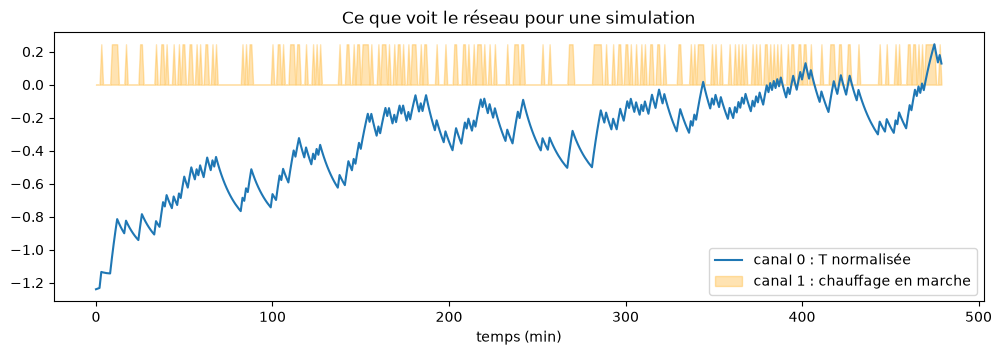

In [3]:
i = 3
xi, zi = ds[i]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(xi[0], label="canal 0 : T normalisée")
ax.fill_between(range(480), 0, xi[1] * xi[0].max().item(), color="orange", alpha=0.3, label="canal 1 : chauffage en marche")
ax.set(xlabel="temps (min)", title="Ce que voit le réseau pour une simulation")
ax.legend()
pd.DataFrame(ds.z.numpy(), columns=MODEL_TARGETS).describe().loc[["mean", "std"]].round(3)

**Lecture.** Les formes sont celles attendues. Les cibles normalisées du batch 1 ont une moyenne proche de 0 et un écart-type proche de 1 (la normalisation est ajustée sur les 16 batches du train, d'où de petits écarts). Le parcours par le `DataLoader` est rapide devant le calcul du réseau.

## 2. Une couche Conv1d : un filtre = une réponse impulsionnelle

Une `Conv1d` fait glisser un petit filtre le long du temps et calcule, à chaque instant, une somme pondérée des valeurs voisines :

$$y_k = \sum_{j} w_j \, x_{k+j}$$

C'est exactement la forme d'un système linéaire : la température est la convolution du chauffage par la **réponse impulsionnelle** du bâtiment. Démonstration : on fixe à la main les poids d'une `Conv1d` à une exponentielle décroissante (bâtiment du premier ordre, τ = 60 min) et on l'applique au canal U.

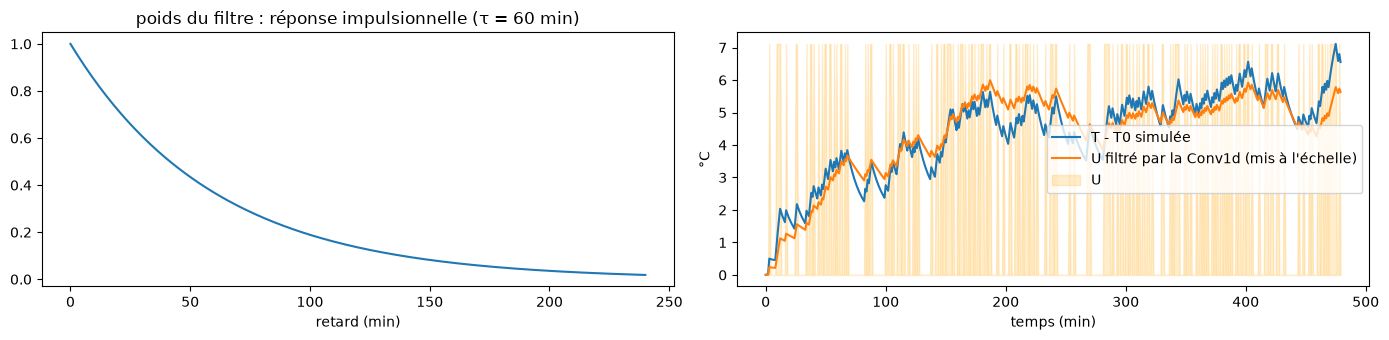

In [4]:
K, tau = 241, 60.0
conv = nn.Conv1d(1, 1, kernel_size=K, bias=False)
with torch.no_grad():
    impulse = torch.exp(-torch.arange(K) / tau)
    conv.weight[:] = (impulse / impulse.sum()).flip(0).view(1, 1, K)   # flip : convolution causale

u = b1.U_on[i].float().view(1, 1, -1)
u_pad = nn.functional.pad(u, (K - 1, 0))           # complète à gauche : la sortie ne dépend que du passé
with torch.no_grad():
    y = conv(u_pad).squeeze()
dT = b1.T[i] - b1.T[i, 0]
scale = (y @ dT) / (y @ y)                          # mise à l'échelle par moindres carrés, pour comparer

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(impulse.numpy())
axes[0].set(title="poids du filtre : réponse impulsionnelle (τ = 60 min)", xlabel="retard (min)")
axes[1].plot(dT, label="T - T0 simulée")
axes[1].plot(scale * y, label="U filtré par la Conv1d (mis à l'échelle)")
axes[1].fill_between(range(480), 0, b1.U_on[i] * dT.max().item(), color="orange", alpha=0.2, label="U")
axes[1].set(xlabel="temps (min)", ylabel="°C")
axes[1].legend()
plt.tight_layout()

**Lecture.** Un seul filtre à une constante de temps reproduit déjà l'allure de la réponse, mais pas tout : le vrai bâtiment a plusieurs modes (air rapide, parois lentes). Dans le réseau, les poids des filtres ne sont **pas fixés à la main** : ils sont appris, et il y en a des dizaines par couche. Le réseau peut ainsi apprendre une banque de « réponses impulsionnelles » qui séparent l'effet de U et la signature du bâtiment, comme le faisait la base de modes de la baseline, mais sans imposer les constantes de temps.

## 3. Le bloc résiduel et le champ réceptif

Le bloc de base (`ResBlock1d`) :

```
x ──► Conv1d ─► GroupNorm ─► GELU ─► Conv1d ─► GroupNorm ──(+)──► GELU ──► sortie
 └──────────────────── raccourci (identité ou Conv 1x1) ───────┘
```

- **GroupNorm** : garde les activations à une échelle stable, l'entraînement converge plus vite. Elle normalise chaque simulation séparément, donc le réseau se comporte de la même façon en entraînement et en évaluation. La BatchNorm, essayée d'abord, dépend des statistiques du lot et rendait la perte d'évaluation instable (voir étape 6).
- **GELU** : la non-linéarité, sans laquelle empiler des couches resterait un modèle linéaire.
- **Raccourci (résiduel)** : le bloc apprend une *correction* de son entrée, ce qui permet d'empiler des blocs sans que l'apprentissage se dégrade.
- **Pas de 2** (stride) sur la première convolution des étages 1 à 5 : la longueur est divisée par 2.

**Champ réceptif.** Un neurone d'une couche ne voit qu'une fenêtre de l'entrée. Avec un noyau de 5, une couche voit 5 min ; empiler les couches et sous-échantillonner agrandit la fenêtre. Pour relier le début et la fin de l'essai (réponse lente), le dernier étage doit voir **toute** la fenêtre de 480 min.

In [5]:
model = ThermalCNN()
pd.DataFrame(stage_shapes(model), columns=["couche", "forme (B, canaux, longueur)"])

,couche,"forme (B, canaux, longueur)"
0,entrée,"(1, 2, 480)"
1,stem,"(1, 32, 240)"
2,étage 0,"(1, 32, 240)"
3,étage 1,"(1, 32, 120)"
4,étage 2,"(1, 64, 60)"
5,étage 3,"(1, 64, 30)"
6,étage 4,"(1, 128, 15)"
7,étage 5,"(1, 128, 8)"


In [6]:
first, last = receptive_field(model)
print(f"une position centrale du dernier étage dépend des minutes {first} à {last} de l'entrée")
print("=> le dernier étage voit toute la fenêtre de 480 min" if (first, last) == (0, 479) else "=> champ réceptif insuffisant")

une position centrale du dernier étage dépend des minutes 0 à 479 de l'entrée
=> le dernier étage voit toute la fenêtre de 480 min


**Lecture.** La longueur passe de 480 à 8 pendant que le nombre de canaux passe de 2 à 128 : le réseau transforme progressivement « une température à chaque minute » en « 128 caractéristiques décrivant la courbe ». Le champ réceptif est mesuré (par le gradient de la sortie par rapport à l'entrée), pas seulement calculé : il couvre bien les 480 minutes.

## 4. Le réseau complet

Après les étages convolutifs, un **pooling global** (moyenne et maximum sur le temps) résume la carte (128 × 8) en un vecteur de 256 nombres, puis une petite tête (MLP) prédit les 5 cibles. Le pooling rend la prédiction insensible à *l'instant* où se produit un motif (un allumage à 10 h ou à 14 h), ce qui est souhaitable : le bâtiment est le même.

In [7]:
print(model)
print(f"\nparamètres entraînables : {count_parameters(model):,}".replace(",", " "))
with torch.no_grad():
    out = model(x)
print("sortie pour un lot :", tuple(out.shape))

ThermalCNN(
  (stem): Sequential(
    (0): Conv1d(2, 32, kernel_size=(7,), stride=(2,), padding=(3,), bias=False)
    (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (2): GELU(approximate='none')
  )
  (blocks): Sequential(
    (0): ResBlock1d(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (bn1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (bn2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (act): GELU(approximate='none')
      (shortcut): Identity()
    )
    (1): ResBlock1d(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(2,), padding=(2,), bias=False)
      (bn1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (bn2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (act): GELU(approximate='none')
  

sortie pour un lot : (256, 5)


In [8]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
times = []
for step in range(12):
    t0 = time.perf_counter()
    opt.zero_grad()
    nn.functional.mse_loss(model(x), z).backward()
    opt.step()
    times.append(time.perf_counter() - t0)
dt = np.median(times[2:])
print(f"un pas d'entraînement (lot de 256) : {dt * 1000:.0f} ms")
print(f"estimation d'une epoch sur le train (800 000 simulations) : {dt * 800_000 / 256 / 60:.1f} min")
model = ThermalCNN()   # on repart d'un réseau neuf pour la suite

un pas d'entraînement (lot de 256) : 697 ms
estimation d'une epoch sur le train (800 000 simulations) : 36.3 min


**Lecture.** Environ 450 000 paramètres : c'est petit devant les 800 000 simulations du train (le risque de sur-apprentissage est limité) et assez rapide pour s'entraîner sur CPU en quelques heures.

## 5. La fonction de perte

On minimise l'**erreur quadratique moyenne (MSE)** sur les cibles normalisées, moyennée sur les 5 sorties.

- Chaque cible est centrée-réduite : toutes pèsent autant dans la perte, quelle que soit leur unité (W/K ou h).
- Pour les τ, la cible est log τ : une erreur sur log τ est une erreur **relative** sur τ (une erreur de 0,1 en log ≈ 10 %), ce qui est cohérent avec le MAPE utilisé en évaluation.
- Un réseau non entraîné prédit à peu près 0 (la moyenne) : sa MSE doit être proche de 1, la variance des cibles normalisées. C'est le niveau de « prédire la moyenne » ; tout entraînement utile doit descendre en dessous.

In [9]:
model.eval()
losses = []
with torch.no_grad():
    for n_batch, (xb, zb) in enumerate(loader):
        losses.append(nn.functional.mse_loss(model(xb), zb).item())
        if n_batch == 9:
            break
print(f"MSE d'un réseau non entraîné (10 lots) : {np.mean(losses):.3f}")
print(f"MSE de la prédiction « moyenne » (0) sur le batch 1 : {ds.z.pow(2).mean().item():.3f}")

MSE d'un réseau non entraîné (10 lots) : 1.127
MSE de la prédiction « moyenne » (0) sur le batch 1 : 1.002


## 6. Test de sur-apprentissage : le réseau peut-il apprendre ?

Contrôle classique avant un long entraînement : sur un tout petit jeu (1000 simulations), un réseau correct doit pouvoir **apprendre par cœur** et amener la perte près de 0. Si ce n'est pas le cas, il y a un bug (données mal alignées, gradient bloqué, mauvais taux d'apprentissage). On coupe le dropout pour ce test.

Ce test ne dit rien sur la généralisation : c'est seulement une vérification de la mécanique.

**Taux d'apprentissage « one-cycle ».** Il monte d'abord puis décroît vers 0 : grands pas au début pour avancer vite, petits pas à la fin pour affiner. Avec un taux constant, un premier essai plafonnait vers 0,13 et la perte d'évaluation sautait de 0,14 à 0,48 (instabilité de la BatchNorm, remplacée depuis par la GroupNorm).

1624 s ; MSE initiale 0.960 -> finale 0.0584


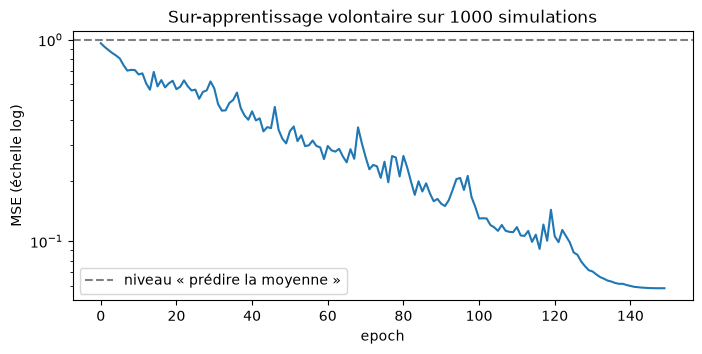

In [10]:
torch.manual_seed(0)
idx = torch.randperm(len(ds))[:1000]
x_small = norm.inputs(b1.T[idx], b1.U_on[idx])
z_small = ds.z[idx]
model = ThermalCNN(CNNConfig(dropout=0.0))
EPOCHS, BS = 150, 100
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.0)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=EPOCHS * (1000 // BS))
history = []
t0 = time.perf_counter()
model.train()
for epoch in range(EPOCHS):
    perm = torch.randperm(1000)
    for k in range(0, 1000, BS):
        j = perm[k : k + BS]
        opt.zero_grad()
        loss = nn.functional.mse_loss(model(x_small[j]), z_small[j])
        loss.backward()
        opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        history.append(nn.functional.mse_loss(model(x_small), z_small).item())
    model.train()
print(f"{time.perf_counter() - t0:.0f} s ; MSE initiale {history[0]:.3f} -> finale {history[-1]:.4f}")

plt.figure(figsize=(8, 3.5))
plt.semilogy(history)
plt.axhline(1, color="grey", ls="--", label="niveau « prédire la moyenne »")
plt.gca().set(xlabel="epoch", ylabel="MSE (échelle log)", title="Sur-apprentissage volontaire sur 1000 simulations")
plt.legend();

**Lecture.** La perte descend régulièrement vers quelques centièmes : le réseau est capable d'apprendre, la mécanique est correcte. Remarque : il faut tout de même ~150 passages pour mémoriser 1000 courbes, ce qui confirme que les courbes de bâtiments différents se ressemblent beaucoup (voir baseline, section 6).

## Bilan de la construction

| Vérification | Résultat attendu |
|---|---|
| Formes entrée / sortie | (B, 2, 480) → (B, 5) |
| Champ réceptif du dernier étage | minutes 0 à 479 |
| Perte avant entraînement | ≈ 1 (niveau de la moyenne) |
| Sur-apprentissage de 1000 exemples | perte → proche de 0 |

La mécanique fonctionne. **Étape suivante** : l'entraînement sur 400 000 simulations du train (`thermal_id.train`), avec évaluation sur la validation à chaque epoch et conservation du modèle de la meilleure epoch (`best.pt`). Le modèle final est entraîné sur la température arrondie à 0,01 °C, comme dans l'énoncé. L'entraînement, les résultats sur le test et leur analyse sont présentés dans le notebook 4.